# Detección de anomalías: z-score vs. Isolation Forest vs. One-Class SVM (RBF)

**Objetivo.** Implementar los tres métodos y medir cómo varía su detección al modificar parámetros.

1. **Dataset provisto:** código copiado de los notebooks de Isolation Forest y One-Class SVM. No se cambia la semilla 42, ningún valor ni ninguna etiqueta.
2. **Baseline auxiliar:** replicación independiente de la fórmula normal de clase, sin anomalías, para ajustar los detectores.
3. **Validación auxiliar:** replicación independiente para comparar parámetros y seleccionar configuraciones.
4. **Prueba complementaria:** otro dataset independiente con anomalías de relación entre KPIs.

Las etiquetas `is_incident` se utilizan para elegir parámetros en validación y medir resultados.

## 1. Librerías y reproducibilidad

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from IPython.display import display

SEED = 42
rng = np.random.default_rng(SEED)
FEATURES = ["requests", "error_rate"]
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 16)

## 2. Dataset original

In [11]:
minutes = pd.date_range("2026-05-12 08:00", periods=180, freq="min")
hour = minutes.hour.to_numpy() + minutes.minute.to_numpy() / 60.0
traffic = 70 + 90 * np.clip(np.sin((hour - 8) * np.pi / 6), 0, None)
n_req = np.maximum(25, np.rint(traffic + rng.normal(0, 8, len(minutes)))).astype(int)
error_rate = np.clip(0.004 + 0.00006 * n_req + rng.normal(0, 0.0012, len(minutes)), 0.001, None)
kind = np.full(len(minutes), "normal", dtype=object)
is_incident = np.zeros(len(minutes), dtype=bool)

# Combinación rara: poco tráfico y muchos errores.
incident = np.asarray((minutes >= "2026-05-12 09:40") & (minutes < "2026-05-12 09:48"))
kind[incident] = "incidente"
is_incident[incident] = True
n_req[incident] = rng.integers(38, 52, incident.sum())
error_rate[incident] = rng.uniform(0.038, 0.050, incident.sum())

# Pico de carga: extremo en volumen, pero sobre la misma relación.
surge = np.asarray((minutes >= "2026-05-12 10:20") & (minutes < "2026-05-12 10:28"))
kind[surge] = "pico de carga"
n_req[surge] = rng.integers(165, 180, surge.sum())
error_rate[surge] = 0.004 + 0.00006 * n_req[surge] + rng.normal(0, 0.0008, surge.sum())

# Timeouts: tráfico medio, error alto. Raro como combinación, no como máximo de un eje.
timeouts = np.asarray((minutes >= "2026-05-12 09:10") & (minutes < "2026-05-12 09:13"))
kind[timeouts] = "timeouts"
error_rate[timeouts] = rng.uniform(0.026, 0.031, timeouts.sum())

data = pd.DataFrame({
    "timestamp": minutes,
    "requests": n_req,
    "error_rate": error_rate,
    "kind": kind,
    "is_incident": is_incident,
})

print("Ventanas:", len(data))
display(data.groupby("kind")[["requests", "error_rate"]].agg(["count", "mean", "max"]).round(4))

Ventanas: 180


requests                error_rate                
                 count      mean  max      count    mean     max
kind                                                            
incidente            8   44.0000   51          8  0.0458  0.0498
normal             161  124.9938  178        161  0.0115  0.0159
pico de carga        8  172.3750  179          8  0.0141  0.0159
timeouts             3  113.3333  116          3  0.0280  0.0283

In [12]:
data_profesor = data.copy(deep=True)
assert len(data_profesor) == 180
assert data_profesor["kind"].value_counts().to_dict() == {
    "normal": 161, "incidente": 8, "pico de carga": 8, "timeouts": 3
}
assert data_profesor["is_incident"].sum() == 8
assert data_profesor["timestamp"].is_unique
print("Dataset del profesor preservado:",len(data_profesor),"filas | incidentes:",int(data_profesor.is_incident.sum()))

Dataset del profesor preservado: 180 filas | incidentes: 8


## 3. Datos auxiliares para entrenamiento y validación

Para evitar entrenar y elegir parámetros con los mismos incidentes que luego se evalúan, se generan dos replicas adicionales con semillas independientes. La  siguiente función conserva la fórmula de tráfico y error normal original. Solo la replicación de validación inyecta los contextos docentes para disponer de etiquetas de calibración.

La SVM utilizada es **One-Class SVM con kernel RBF**, apropiada para detección no supervisada de rarezas; no es una `SVC` supervisada.

In [13]:
def generar_auxiliar(fecha, semilla, eventos=False):
    rg = np.random.default_rng(semilla)
    minutes = pd.date_range(f"{fecha} 08:00", periods=180, freq="min")
    hour = minutes.hour.to_numpy() + minutes.minute.to_numpy() / 60.0
    traffic = 70 + 90 * np.clip(np.sin((hour - 8) * np.pi / 6), 0, None)
    n_req = np.maximum(25, np.rint(traffic + rg.normal(0, 8, len(minutes)))).astype(int)
    error_rate = np.clip(0.004 + 0.00006 * n_req + rg.normal(0, 0.0012, len(minutes)), 0.001, None)
    kind = np.full(len(minutes), "normal", dtype=object)
    is_incident = np.zeros(len(minutes), dtype=bool)
    if eventos:
        incident = np.asarray((minutes >= f"{fecha} 09:40") & (minutes < f"{fecha} 09:48"))
        kind[incident] = "incidente"
        is_incident[incident] = True
        n_req[incident] = rg.integers(38, 52, incident.sum())
        error_rate[incident] = rg.uniform(0.038, 0.050, incident.sum())

        surge = np.asarray((minutes >= f"{fecha} 10:20") & (minutes < f"{fecha} 10:28"))
        kind[surge] = "pico de carga"
        n_req[surge] = rg.integers(165, 180, surge.sum())
        error_rate[surge] = 0.004 + 0.00006 * n_req[surge] + rg.normal(0, 0.0008, surge.sum())

        timeouts = np.asarray((minutes >= f"{fecha} 09:10") & (minutes < f"{fecha} 09:13"))
        kind[timeouts] = "timeouts"
        error_rate[timeouts] = rg.uniform(0.026, 0.031, timeouts.sum())
    return pd.DataFrame({"timestamp": minutes, "requests": n_req,
                         "error_rate": error_rate, "kind": kind, "is_incident": is_incident})

baseline = generar_auxiliar("2026-05-13", 202, eventos=False)
validacion = generar_auxiliar("2026-05-14", 303, eventos=True)
assert not baseline.is_incident.any()
assert validacion.is_incident.sum() == 8
# Los tres DataFrames son independientes; en particular la prueba no se ha retocado.
assert len(data_profesor) == len(baseline) == len(validacion) == 180
scaler = StandardScaler().fit(baseline[FEATURES])
X_base = scaler.transform(baseline[FEATURES])
X_val = scaler.transform(validacion[FEATURES])
X_prof = scaler.transform(data_profesor[FEATURES])
mu = float(baseline["error_rate"].mean())
sigma = float(baseline["error_rate"].std(ddof=1))
assert sigma > 0
print("Entrenamiento normal:",len(baseline),"| Validación:",len(validacion),
      "| Prueba del profesor:",len(data_profesor))

Entrenamiento normal: 180 | Validación: 180 | Prueba del profesor: 180


## 4. Métodos y búsqueda de hiperparámetros

- **z-score:** alerta cuando el desvío absoluto de `error_rate` respecto del baseline supera el umbral elegido. Explora distintos valores de $|z|$. Solo ve un KPI.
- **Isolation Forest:** usa `n_estimators` (árboles), `max_samples` (submuestras por árbol) y `contamination` (corte para alertas). Usa **dos KPIs**.
- **One-Class SVM RBF:** usa `nu` (restricciones sobre errores y support vectors del entrenamiento) y `gamma` (anchura/alcance del kernel RBF). Usa **dos KPIs** escalados.

Cada modelo se ajusta solo sobre el baseline normal y se selecciona con F1 operacional en validación. Si hay empate, se prefiere menor cantidad de falsos positivos. El mejor conjunto de parámetros es el mejor entre los escenarios probados.

In [14]:
metodos = ["z-score", "Isolation Forest", "One-Class SVM RBF"]
configuraciones = (
    [("z-score", {"umbral": t}) for t in [2.5, 3, 4, 5, 6, 7, 8]] +
    [("Isolation Forest", {"n_estimators": m, "max_samples": psi, "contamination": c})
     for m in [100, 200] for psi in [64, 128] for c in [0.02, 0.05, 0.10]] +
    [("One-Class SVM RBF", {"nu": nu, "gamma": gamma})
     for nu in [0.02, 0.05, 0.10] for gamma in [0.1, 0.5, 1.5]]
)

def crear_detector(metodo, params):
    if metodo == "z-score":
        return None
    if metodo == "Isolation Forest":
        return IsolationForest(**params, random_state=SEED, n_jobs=-1).fit(X_base)
    if metodo == "One-Class SVM RBF":
        return OneClassSVM(kernel="rbf", **params).fit(X_base)
    raise ValueError(metodo)

def detectar(metodo, modelo, parametros, X, dataframe):
    if metodo == "z-score":
        score = np.abs((dataframe["error_rate"].to_numpy() - mu) / sigma)
        return score > parametros["umbral"]
    return modelo.predict(X) == -1

def medir(y, pred):
    y = np.asarray(y, dtype=bool)
    pred = np.asarray(pred, dtype=bool)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[False,True]).ravel()
    return {"TP": int(tp), "FP": int(fp), "FN": int(fn),
            "alertas": int(pred.sum()),
            "precisión": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0),
            "FPR": fp / (fp + tn) if fp + tn else np.nan}

experimentos = []
for metodo, parametros in configuraciones:
    modelo = crear_detector(metodo, parametros)
    pred = detectar(metodo, modelo, parametros, X_val, validacion)
    experimentos.append({"método": metodo, "parámetros": parametros,
                          **medir(validacion.is_incident, pred)})
resultados_val = pd.DataFrame(experimentos)
mejores = {}
filas_mejores = []
for metodo in metodos:
    subset = resultados_val[resultados_val["método"].eq(metodo)].copy()
    # desempate determinista: conserva primero el orden de búsqueda
    fila = subset.sort_values(["F1", "FP", "alertas"], ascending=[False, True, True], kind="stable").iloc[0]
    mejores[metodo] = fila["parámetros"]
    filas_mejores.append(fila)
print("Escenarios evaluados en VALIDACIÓN:",len(resultados_val))
for metodo in metodos:
    print(f"  {metodo}: {mejores[metodo]}")
display(pd.DataFrame(filas_mejores)[["método","parámetros","TP","FP","FN","F1"]].round(3).reset_index(drop=True))

Escenarios evaluados en VALIDACIÓN: 28
  z-score: {'umbral': 7}
  Isolation Forest: {'n_estimators': 100, 'max_samples': 64, 'contamination': 0.02}
  One-Class SVM RBF: {'nu': 0.02, 'gamma': 0.1}


,método,parámetros,TP,FP,FN,F1
0,z-score,{'umbral': 7},8,2,0,0.889
1,Isolation Forest,"{'n_estimators': 100, 'max_samples': 64, 'cont...",8,10,0,0.615
2,One-Class SVM RBF,"{'nu': 0.02, 'gamma': 0.1}",8,8,0,0.667


## 5. Sensibilidad - cuánto cambian las alertas

Una muestra controlada de configuraciones permite observar sensibilidad. El gráfico refleja validación. Los parámetros que influyen en el número de alertas no son equivalentes a la proporción real de incidentes.

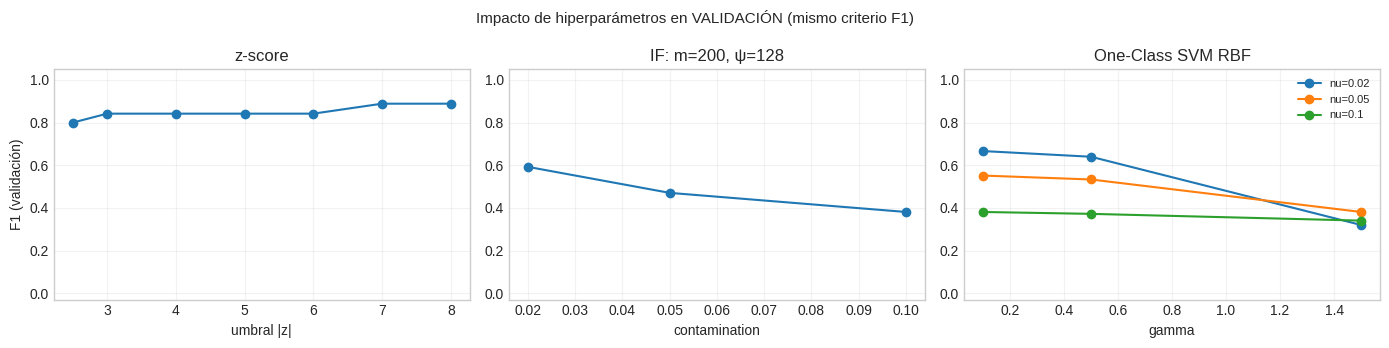

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
z = resultados_val[resultados_val["método"].eq("z-score")]
axes[0].plot(z["parámetros"].map(lambda p:p["umbral"]), z["F1"], "o-")
axes[0].set(xlabel="umbral |z|", ylabel="F1 (validación)", title="z-score")
ifx = resultados_val[resultados_val["método"].eq("Isolation Forest")]
ifx = ifx[ifx["parámetros"].map(lambda p: p["n_estimators"]==200 and p["max_samples"]==128)]
axes[1].plot(ifx["parámetros"].map(lambda p:p["contamination"]), ifx["F1"], "o-")
axes[1].set(xlabel="contamination", title="IF: m=200, ψ=128")
svm = resultados_val[resultados_val["método"].eq("One-Class SVM RBF")]
for nu in [0.02,0.05,0.10]:
    d = svm[svm["parámetros"].map(lambda p:p["nu"]==nu)]
    axes[2].plot(d["parámetros"].map(lambda p:p["gamma"]), d["F1"], "o-", label=f"nu={nu:g}")
axes[2].set(xlabel="gamma", title="One-Class SVM RBF")
axes[2].legend(fontsize=8)
for ax in axes:
    ax.set_ylim(-0.03,1.05)
    ax.grid(alpha=.25)
plt.suptitle("Impacto de hiperparámetros en VALIDACIÓN (mismo criterio F1)",fontsize=11)
plt.tight_layout()
plt.show()

## 6. Evaluación del dataset original

Ahora se aplican los tres detectores, con parámetros fijados en la validación independiente, a las 180 observaciones originales.

Comparación sobre 180 ventanas ORIGINALES del profesor:


,método,TP,FP,FN,precisión,recall,F1,FPR
0,z-score,8,3,0,0.727,1.0,0.842,0.017
1,Isolation Forest,8,7,0,0.533,1.0,0.696,0.041
2,One-Class SVM RBF,8,5,0,0.615,1.0,0.762,0.029


Cantidad de alertas por contexto docente:


,minutos,z-score,Isolation Forest,One-Class SVM RBF
contexto,,,,
normal,161,0,4,1
timeouts,3,3,2,3
incidente,8,8,8,8
pico de carga,8,0,1,1


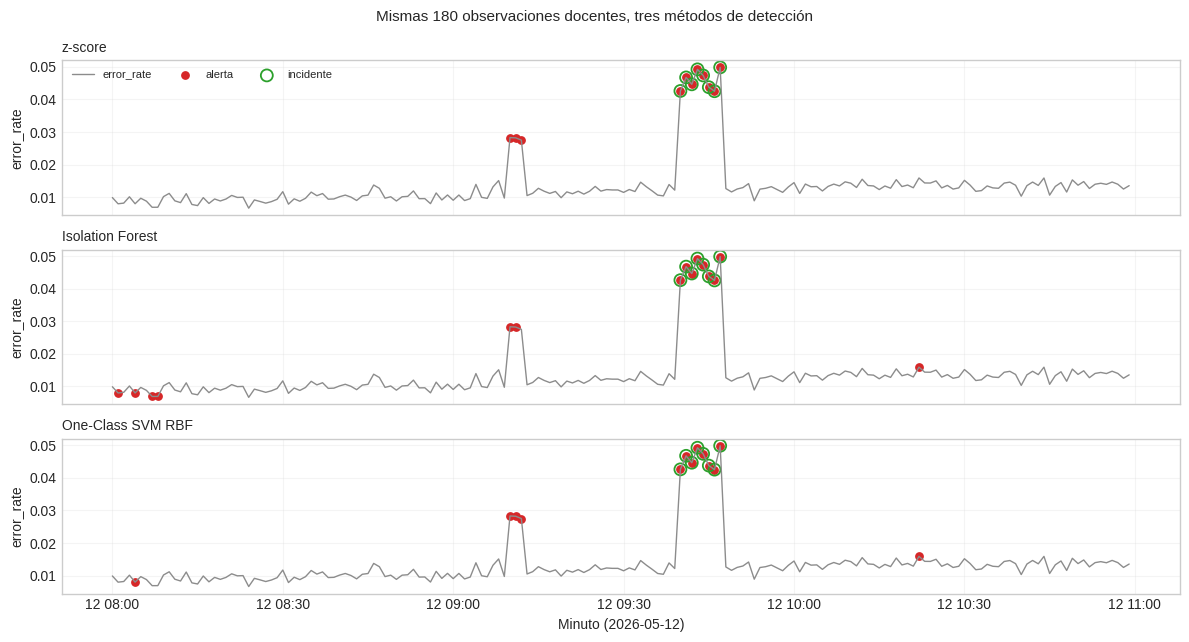

In [16]:
modelos_finales = {}
predicciones_profesor = {}
resumen = []
for metodo in metodos:
    params = mejores[metodo]
    modelo = crear_detector(metodo, params)  # ajuste exclusivamente sobre baseline auxiliar
    pred = detectar(metodo, modelo, params, X_prof, data_profesor)
    modelos_finales[metodo] = modelo
    predicciones_profesor[metodo] = pred
    resumen.append({"método": metodo, **medir(data_profesor.is_incident, pred)})
resumen_profesor = pd.DataFrame(resumen)
print("Comparación sobre 180 ventanas ORIGINALES del profesor:")
display(resumen_profesor[["método","TP","FP","FN","precisión","recall","F1","FPR"]].round(3))

# Resumen breve por contexto: muestra qué tipo de evento produce falsas alertas.
contextos=[]
for contexto, sub in data_profesor.groupby("kind",sort=False):
    pos=data_profesor.index.isin(sub.index)
    contextos.append({"contexto":contexto,"minutos":len(sub),
                      **{m:int(predicciones_profesor[m][pos].sum()) for m in metodos}})
print("Cantidad de alertas por contexto docente:")
display(pd.DataFrame(contextos).set_index("contexto"))

fig, axs = plt.subplots(3, 1, figsize=(12, 6.5), sharex=True, sharey=True)
for ax, metodo in zip(axs, metodos):
    flag = predicciones_profesor[metodo]
    ax.plot(data_profesor["timestamp"],data_profesor["error_rate"],color="0.55",lw=1,label="error_rate")
    ax.scatter(data_profesor.loc[flag,"timestamp"],data_profesor.loc[flag,"error_rate"],
               color="tab:red",s=28,label="alerta")
    ax.scatter(data_profesor.loc[data_profesor.is_incident,"timestamp"],
               data_profesor.loc[data_profesor.is_incident,"error_rate"],
               facecolors="none",edgecolors="tab:green",s=74,linewidth=1.3,label="incidente")
    ax.set_title(metodo,loc="left",fontsize=10)
    ax.set_ylabel("error_rate")
    ax.grid(alpha=.2)
axs[0].legend(loc="upper left",ncol=3,fontsize=8)
axs[-1].set_xlabel("Minuto (2026-05-12)")
fig.suptitle("Mismas 180 observaciones docentes, tres métodos de detección",fontsize=11)
plt.tight_layout()
plt.show()
assert data_profesor.equals(data), "El dataset docente ha sido modificado"

## 7. Prueba adicional

Para medir una limitación que el incidente del dataset original puede ocultar, generamos otro dataset. Durante 8 minutos la tasa de error es moderada en términos globales, pero es inusualmente alta para ese bajo nivel de carga. Este escenario puede no superar el umbral univariado de z-score, aunque la combinación sea poco frecuente. Los modelos conservan sus parámetros del experimento anterior y no se vuelven a calibrar.

Comparación sobre el segundo dataset (180 ventanas):


,método,TP,FP,FN,precisión,recall,F1,FPR
0,z-score,0,0,8,0.000,0.0,0.000,0.000
1,Isolation Forest,8,3,0,0.727,1.0,0.842,0.017
2,One-Class SVM RBF,8,5,0,0.615,1.0,0.762,0.029


Alertas por contexto:


,minutos,z-score,Isolation Forest,One-Class SVM RBF
contexto,,,,
normal,172,0,3,5
desacople_KPI,8,0,8,8


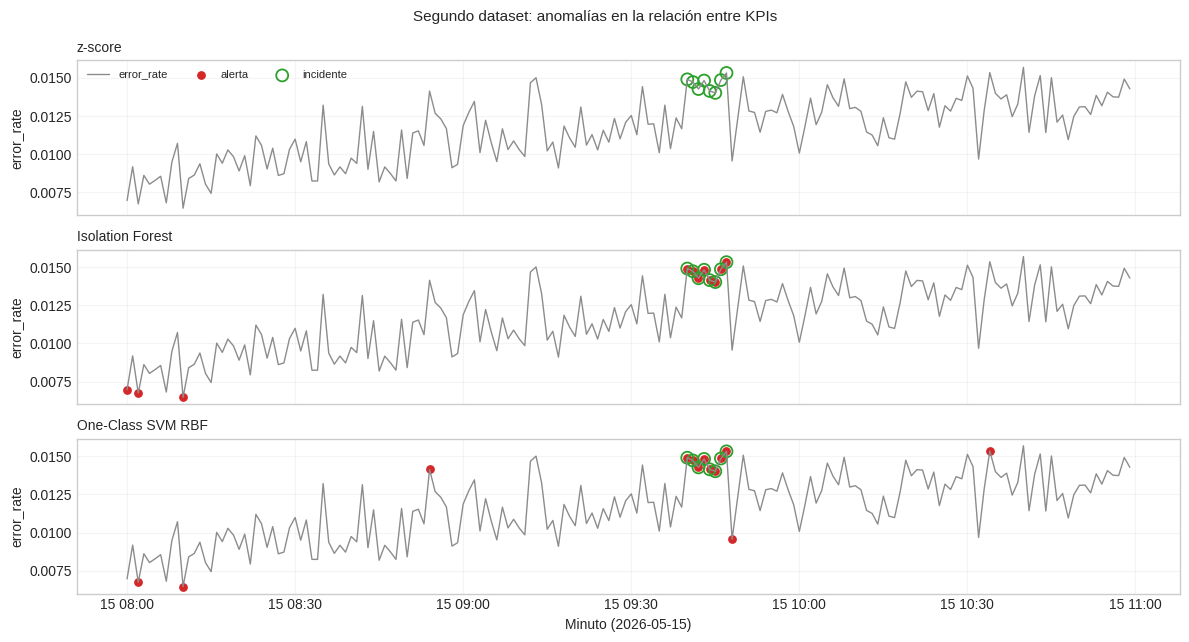

In [17]:

# Comparativa completa del segundo dataset
predicciones_extra = {}
filas_extra = []

for metodo in metodos:
    pred = detectar(
        metodo, modelos_finales[metodo],
        mejores[metodo], X_extra, data_extra
    )
    predicciones_extra[metodo] = pred
    filas_extra.append({
        "método": metodo,
        **medir(data_extra["is_incident"], pred)
    })

resumen_extra = pd.DataFrame(filas_extra)

print("Comparación sobre el segundo dataset (180 ventanas):")
display(
    resumen_extra[
        ["método", "TP", "FP", "FN",
         "precisión", "recall", "F1", "FPR"]
    ].round(3)
)

# Cantidad de alertas por contexto
contextos_extra = []

for contexto, sub in data_extra.groupby("kind", sort=False):
    pos = data_extra.index.isin(sub.index)
    contextos_extra.append({
        "contexto": contexto,
        "minutos": len(sub),
        **{
            metodo: int(predicciones_extra[metodo][pos].sum())
            for metodo in metodos
        }
    })

print("Alertas por contexto:")
display(pd.DataFrame(contextos_extra).set_index("contexto"))

# Visualización de los tres algoritmos
fig, axs = plt.subplots(
    3, 1, figsize=(12, 6.5),
    sharex=True, sharey=True
)

for ax, metodo in zip(axs, metodos):
    flag = predicciones_extra[metodo]

    ax.plot(
        data_extra["timestamp"],
        data_extra["error_rate"],
        color="0.55", lw=1, label="error_rate"
    )

    ax.scatter(
        data_extra.loc[flag, "timestamp"],
        data_extra.loc[flag, "error_rate"],
        color="tab:red", s=28, label="alerta"
    )

    ax.scatter(
        data_extra.loc[data_extra["is_incident"], "timestamp"],
        data_extra.loc[data_extra["is_incident"], "error_rate"],
        facecolors="none", edgecolors="tab:green",
        s=74, linewidth=1.3, label="incidente"
    )

    ax.set_title(metodo, loc="left", fontsize=10)
    ax.set_ylabel("error_rate")
    ax.grid(alpha=0.2)

axs[0].legend(loc="upper left", ncol=3, fontsize=8)
axs[-1].set_xlabel("Minuto (2026-05-15)")

fig.suptitle(
    "Segundo dataset: anomalías en la relación entre KPIs",
    fontsize=11
)

plt.tight_layout()
plt.show()



## 8. Conclusiones

### 8.1. Resultados sobre el dataset original

En el dataset proporcionado por el docente, los tres algoritmos lograron detectar los 8 minutos identificados como incidentes operacionales, alcanzando un recall del 100%. Sin embargo, se observaron diferencias en la cantidad de falsos positivos generados.

El método z-score obtuvo el mejor resultado, con un F1 de 0,842 y solo 3 falsos positivos. En segundo lugar quedó One-Class SVM con kernel RBF, con un F1 de 0,762 y 5 falsos positivos. Por último, Isolation Forest obtuvo un F1 de 0,696 y 7 falsos positivos.

Consideramos que el buen desempeño de z-score se explica porque los incidentes del dataset original presentan aumentos importantes en la tasa de errores. Estas desviaciones pueden identificarse utilizando únicamente esa variable, sin necesidad de analizar relaciones más complejas entre métricas.

En este escenario, los modelos multivariados detectaron todos los incidentes, pero también identificaron como anómalos algunos comportamientos que no estaban etiquetados como incidentes operacionales, generando una mayor cantidad de falsas alertas respecto a esa clasificación.

### 8.2. Resultados sobre el segundo dataset

Para complementar la evaluación, utilizamos un segundo dataset sintético con un escenario diferente que tiene una tasa de errores que, aunque no es extrema por sí sola, resulta inusual cuando se considera junto con un volumen bajo de solicitudes.

Los resultados fueron diferentes a los obtenidos inicialmente.

Isolation Forest obtuvo el mejor desempeño, con un F1 de 0,842, detectando los 8 incidentes y generando 3 falsos positivos. One-Class SVM RBF quedó en segundo lugar, con un F1 de 0,762 y 5 falsos positivos.

Por su parte, z-score no consiguió detectar ninguno de los 8 incidentes, obteniendo un F1 de 0.

Esto demuestra una limitante del enfoque univariado donde una métrica puede mantenerse dentro de los valores considerados normales y, aun así, representar una anomalía cuando se analiza su relación con otras variables.

En cambio, Isolation Forest y One-Class SVM consiguieron identificar estos comportamientos utilizando conjuntamente el volumen de solicitudes y la tasa de errores.

### 8.3. Conclusión general

A partir de los experimentos realizados, entendemos que no existe un algoritmo que resulte superior en todos los escenarios. Su desempeño depende de las características de los datos y del tipo de anomalía que se busca identificar.

Z-score resultó efectivo para detectar desviaciones pronunciadas en una única métrica, con una implementación sencilla y una baja cantidad de falsos positivos en el primer escenario.

Isolation Forest y One-Class SVM demostraron una mayor capacidad para detectar anomalías relacionadas con combinaciones poco habituales de métricas. En particular, Isolation Forest obtuvo el mejor resultado en el segundo experimento.

También observamos que la selección de hiperparámetros influye en la cantidad de alertas generadas. Por ese motivo, consideramos de gran importancia calibrarlos utilizando datos representativos y evaluar tanto la detección de incidentes como los falsos positivos.

Como conclusión, consideramos que z-score es una buena alternativa para detectar anomalías evidentes en métricas individuales, mientras que Isolation Forest y One-Class SVM resultan útiles cuando el comportamiento anómalo depende de la relación entre varias métricas.

Para un sistema de monitoreo operacional, entendemos que estos enfoques pueden ser complementarios. La elección debería basarse en el comportamiento de los datos y en un equilibrio entre la detección de incidentes y la generación de alertas innecesarias.
